## Devon Energy (DVN) 20261007 Analysis

In [1]:
import os
import sys
import requests
import datetime as dt
import numpy as np
from dotenv import load_dotenv
from pathlib import Path
import requests
import pandas as pd
import talib as ta
import plotly.graph_objs as go

import ipywidgets as widgets
from ipywidgets import Dropdown, Text, Button, Output
from IPython.display import display

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

#### WTIの時系列データを取得

In [3]:
wti = 'CL=F'
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
response = request_api.update_commodity_timeseries_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [4]:
wti_df = request_api.get_commodity_time_series_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
wti_df.head()

取得件数: 6574


,id,commodity_id,commodity_code,commodity_market,date,open,high,low,close,adj_close,...,rci26,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,6530,2,CL=F,None,2000-08-23,32.049999,32.799999,31.950001,31.950001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,6531,2,CL=F,None,2000-08-24,31.629999,32.240002,31.400000,31.900000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,6532,2,CL=F,None,2000-08-25,32.049999,32.099998,31.320000,31.700001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,6533,2,CL=F,None,2000-08-28,32.869999,32.919998,31.860001,32.040001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,6534,2,CL=F,None,2000-08-29,32.720001,33.029999,32.560001,32.820000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500の時系列データを取得

In [5]:
sp500 = '^GSPC'

response = request_api.update_stock_timeseries_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [6]:
sp_timeseries_df = request_api.get_stock_time_series_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
sp_timeseries_df.head()

取得件数: 7205


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1357606,^GSPC,None,1998-03-09,1052.310059,1058.550049,1050.020020,1055.689941,624700000,NaN,...,NaN,NaN,False,NaN,NaN,12.528853,NaN,25.0,NaN,False
1,1357607,^GSPC,None,1998-03-10,1064.250000,1064.589966,1052.310059,1052.310059,631920000,NaN,...,NaN,NaN,False,6932.008008,NaN,NaN,10.503143,NaN,-0.786325,False
2,1357608,^GSPC,None,1998-03-11,1068.469971,1069.180054,1064.219971,1064.250000,655260000,NaN,...,NaN,NaN,False,NaN,6922.560059,NaN,NaN,-5.0,NaN,False
3,1357609,^GSPC,None,1998-03-12,1069.920044,1071.869995,1063.540039,1068.469971,594940000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1357610,^GSPC,None,1998-03-13,1068.609985,1075.859985,1066.569946,1069.920044,597800000,1062.128003,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### DVNの時系列データを取得

In [7]:
dvn = 'DVN'

response = request_api.update_stock_timeseries_data(
    code=dvn,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [8]:
dvn_timeseries_df = request_api.get_stock_time_series_data(
    code=dvn,
    market=None,
    start=start,
    end=end
)
dvn_timeseries_df

取得件数: 7028


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1134459,DVN,None,1998-11-17,9.827518,9.937118,9.790984,9.937118,194600,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1134460,DVN,None,1998-11-18,9.845779,9.864046,9.809246,9.845779,279200,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1134461,DVN,None,1998-11-19,9.809252,9.864052,9.790985,9.864052,273200,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1134462,DVN,None,1998-11-20,9.790983,9.809250,9.717916,9.790983,286200,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1134463,DVN,None,1998-11-23,9.790983,9.900584,9.790983,9.790983,433400,9.845783,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7023,1322453,DVN,None,2026-10-21,49.869999,50.439999,49.180000,50.000000,10503800,50.342001,...,46.933889,50.840946,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7024,1332287,DVN,None,2026-10-22,49.180000,50.509998,48.400002,50.419998,9476000,50.414000,...,46.979487,50.286007,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7025,1332288,DVN,None,2026-10-23,51.389999,51.689999,49.250000,49.599998,13273100,50.434000,...,47.005055,49.159054,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7026,1340462,DVN,None,2026-10-26,51.639999,51.970001,50.939999,51.389999,8413400,50.581999,...,47.057833,49.133441,True,NaN,NaN,NaN,NaN,NaN,NaN,False


In [9]:
def stock_prices_and_oil_prices(
        code: str,
        name: str,
        start: str,
        end: str,
        df_sp: pd.DataFrame | None = None,
        df_wti: pd.DataFrame | None = None,
        #df_silver: pd.DataFrame | None = None,
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=None,
        start=start,
        end=end
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # WTI原油価格を統合
    if df_wti is not None:
        df_wti_tmp = df_wti.copy() if df_wti is not None else pd.DataFrame()
        if "date" not in df_wti_tmp.columns:
            df_wti_tmp = df_wti_tmp.reset_index()
        df_wti_tmp["date"] = pd.to_datetime(df_wti_tmp["date"])
        df_wti_tmp = df_wti_tmp.set_index("date")
        df_wti_tmp = df_wti_tmp.loc[start:end]

    # 株価時系列データを整形
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA50_SP"] = df_sp_tmp["ma50"].reindex(df.index)
        df["MA200_SP"] = df_sp_tmp["ma200"].reindex(df.index)
    if df_wti is not None:
        df["MA50_WTI"] = df_wti_tmp["ma50"].reindex(df.index)
        df["MA200_WTI"] = df_wti_tmp["ma200"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end,
        ma5=False,
        ma25=False,
        ma50=True,
        ma100=False,
        ma150=False,
        ma200=True,
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / WTI",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_SP"],
                name="SP_MA50",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_SP"],
                name="SP_MA200",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- WTI（右軸） ---
    if df_wti is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_WTI"],
                name="WTI_MA50",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_WTI"],
                name="WTI_MA200",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    return fig

In [10]:
name = "Devon Energy"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=dvn,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=wti_df
)
fig.show()

取得件数: 663


In [11]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{dvn}_{start}_{end}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/DVN_2025-01-01_2026-10-28.png


#### 株価のみのチャート

In [12]:
name = "Devon Energy"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=dvn,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=None
)
fig.show()

取得件数: 663


#### 時系列データを保存

In [13]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{dvn}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
dvn_df = dvn_timeseries_df.copy()
dvn_df = dvn_df.reset_index()
dvn_df["date"] = pd.to_datetime(dvn_df["date"])
dvn_df = dvn_df.set_index("date")
dvn_df = dvn_df.loc['2026-01-01':end]
dvn_df.to_csv(output_path)
# 保存完了のメッセージを表示
print("saved:", output_path)
dvn_df.head()

saved: /workspace/data/DVN_data_2026-10-28.csv


,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,6822,1141281,DVN,None,37.166458,37.480513,35.812098,35.998567,8717300,35.768915,...,35.396285,82.677367,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-05,6823,1141282,DVN,None,35.870983,37.372562,34.791420,37.087948,11876600,36.086897,...,35.491389,82.557842,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-06,6824,1141283,DVN,None,35.223244,36.243924,35.095658,35.802283,8595600,36.175224,...,35.507044,80.525911,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,6825,1141284,DVN,None,33.829628,35.233062,33.594085,35.174175,13022000,36.047640,...,35.443343,78.152480,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,6826,1141285,DVN,None,35.419529,35.870982,34.006282,34.182939,9846400,35.649182,...,35.255830,72.953129,False,NaN,NaN,NaN,NaN,NaN,NaN,False


{'fib_levels_down': {'1.000': np.float64(39.74261021430171),
  '1.272': np.float64(36.41675986056053),
  '1.382': np.float64(35.071746849856375),
  '1.618': np.float64(32.18608257234564)},
 'fib_levels_up': {'1.272': np.float64(55.295851574444306),
  '1.382': np.float64(56.640864585148464),
  '1.618': np.float64(59.5265288626592),
  '2.000': np.float64(64.19739222710453)},
 'swing_high': np.float64(51.970001220703125),
 'swing_low': np.float64(39.74261021430171),
 'df_with_fib':           date  index       id stock_code stock_market       open       high  \
 0   2026-01-02   6822  1141281        DVN         None  37.166458  37.480513   
 1   2026-01-05   6823  1141282        DVN         None  35.870983  37.372562   
 2   2026-01-06   6824  1141283        DVN         None  35.223244  36.243924   
 3   2026-01-07   6825  1141284        DVN         None  33.829628  35.233062   
 4   2026-01-08   6826  1141285        DVN         None  35.419529  35.870982   
 ..         ...    ...      ...

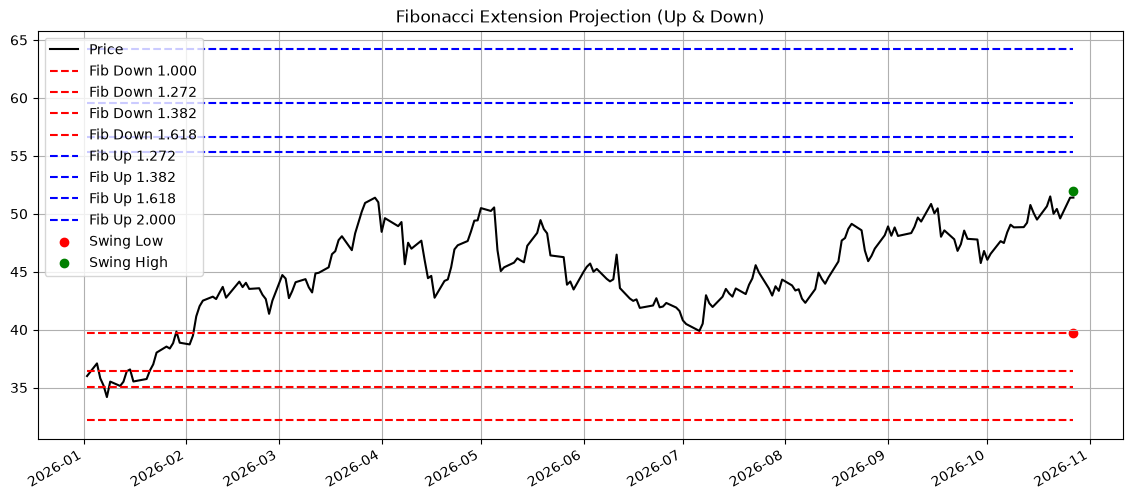

In [14]:
fib_result = fibonacci_extension.compute_fibonacci_extension(dvn_df.copy().reset_index())
fib_result

In [15]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{dvn}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
# 重複するファイルがある場合は削除
if output_path.exists():
    output_path.unlink()
# 保存
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/DVN_fibonacci_extension_2026-10-28.png


#### 財務データ

In [16]:
response = request_api.update_corp_finance_data(
    code=dvn,
    market=None
)
response

{'result': True}

In [17]:
dvn_financials_data = request_api.get_corp_financials_data(code=dvn, market=None)
dvn_balance_sheet_data = request_api.get_corp_balance_sheet_data(code=dvn, market=None)
dvn_cash_flow_data = request_api.get_corp_cash_flow_data(code=dvn, market=None)
dvn_earnings_data = request_api.get_corp_earnings_data(code=dvn, market=None)
dvn_quarterly_earnings_data = request_api.get_corp_quarterly_earnings_data(code=dvn, market=None)

In [18]:
# ４年分の財務データ
dvn_financials_data_df = pd.DataFrame(dvn_financials_data['results'])
# ４年分のバランスシート
dvn_balance_sheet_data_df = pd.DataFrame(dvn_balance_sheet_data['results'])
# ４年分のキャッシュフロー
dvn_cash_flow_data_df = pd.DataFrame(dvn_cash_flow_data['results'])
# ４年分の収益データ
dvn_earnings_data_df = pd.DataFrame(dvn_earnings_data['results'])
# ４年分の四半期収益データ
dvn_quarterly_earnings_data_df = pd.DataFrame(dvn_quarterly_earnings_data['results'])

In [19]:
"""
◆ 1. 株価・市場データ
• 現在株価（Price）
• 時価総額（Market Cap）
• 出来高（Volume）
• 52週高値・安値
• Beta（ボラティリティ指標）ß
"""
stock_prices_market_data.stock_prices_and_market_data(
    code=dvn,
    market=None,
    bs_df=dvn_balance_sheet_data_df
)

取得件数: 461
取得件数: 461
取得件数: 460
取得件数: 460
取得件数: 458
取得件数: 458
取得件数: 459
取得件数: 459
取得件数: 458
取得件数: 458


,close,market_cap,shares_outstanding,higher_rate_par_52_weeks,lower_rate_par_52_weeks,beta
0,10.809738,NaN,NaN,36.476276,3.387556,2.141601
1,18.639151,1.217137e+10,653000000.0,67.038290,15.441668,1.159576
2,46.490163,2.956774e+10,636000000.0,67.038290,38.601319,1.190871
3,45.926590,2.989821e+10,651000000.0,51.291538,29.016771,0.991110
4,43.076505,2.679359e+10,622000000.0,51.291538,24.896948,1.158578


In [20]:
"""
◆ 2. 財務データ（Financials）+ EPS（Earnings Per Share）+ PBR（Price-to-Book Ratio）
• 売上高（Revenue）
• 営業利益（Operating Income）
• 純利益（Net Income）
• EBITDA（企業による）
• 総資産（Total Assets）
• 総負債（Total Liabilities）
• 現金（Cash）
• 希釈EPS（Diluted EPS）
• 基本EPS（Basic EPS）
• 営業キャッシュフロー（Operating Cash Flow）
• フリーキャッシュフロー（Free Cash Flow）
"""
financial_df = financial.calc_financial(
    code = dvn,
    market = None,
)
financial_df.to_markdown()

取得件数: 6954


'|    | date                |      revenue |    earnings |   total_assets |   total_debt |   cash_and_cash_equivalents |     EBITDA |   operating_income |   basic_eps |   diluted_eps |   operating_cash_flow |   free_cash_flow |\n|---:|:--------------------|-------------:|------------:|---------------:|-------------:|----------------------------:|-----------:|-------------------:|------------:|--------------:|----------------------:|-----------------:|\n|  0 | 2021-12-31 00:00:00 | nan          | nan         |   nan          |  nan         |                 nan         | 0          |        nan         |   nan       |     nan       |           nan         |      nan         |\n|  1 | 2022-12-31 00:00:00 |   1.9169e+10 |   6.015e+09 |     2.3721e+10 |    6.697e+09 |                   1.454e+09 | 1.0368e+10 |          7.92e+09  |     9.15177 |       9.12    |             8.53e+09  |        3.405e+09 |\n|  2 | 2023-12-31 00:00:00 |   1.5258e+10 |   3.747e+09 |     2.449e+10  |    6.45e+09 